# Predicting airline delay propagation
**CSCI 5622 project · Sawyer McKenney**

**The decision.** When an aircraft reaches the gate, should the airline's operations team flag it as at risk of making its *next* departure 15+ minutes late?

**The data.** `data/turnarounds.csv.gz` is built by `prepare_data.py` from 2023-2025 BTS On-Time Performance and NOAA hourly weather. Each row is one *turnaround*: an arriving flight plus the same tail number's next departure from that airport. It is a random sample of 450,000 turnarounds from 2023, 2024 and 2025.

## Setup

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 5622
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (6.5, 4.2)

FN_COST = 5   # a missed delay costs 5
FP_COST = 1   # a false alarm costs 1

## 1. Load the data

| column | meaning |
|---|---|
| `y` | **label**: 1 if the next flight left the gate 15+ minutes late |
| `inbound_arr_delay` | minutes late the inbound flight arrived (negative = early) |
| `sched_turn_min` | scheduled minutes on the ground |
| `slack_min` | `sched_turn_min - inbound_arr_delay`: ground time actually left |
| `next_dep_hour`, `day_of_week`, `leg_of_day`, `next_distance` | schedule facts about the next flight |
| `wind_speed`, `visibility`, `precipitation`, `weather_missing` | latest weather observation *before* the arrival |
| `carrier`, `airport`, `next_flight_date` | used for splitting and slicing, not as model inputs |

In [13]:
DATA = "data/turnarounds.csv.gz"   # in Colab, replace with the raw GitHub URL of this file
df = pd.read_csv(DATA, parse_dates=["next_flight_date"])
print(df.shape)
df.head()

(450000, 15)


,next_flight_date,carrier,airport,inbound_arr_delay,sched_turn_min,slack_min,next_dep_hour,day_of_week,leg_of_day,next_distance,y,wind_speed,visibility,precipitation,weather_missing
0,2023-01-01,B6,JFK,-20.0,120.0,140.0,9.0,6.0,1,2475.0,0,5.1,4.828,0.0,0
1,2023-01-01,9E,DTW,5.0,50.0,45.0,8.0,6.0,1,228.0,1,1.5,8.000,0.0,0
2,2023-01-01,WN,STL,-9.0,55.0,64.0,7.0,6.0,1,869.0,0,1.5,6.437,0.0,0
3,2023-01-01,UA,CLE,-30.0,85.0,115.0,9.0,6.0,1,404.0,0,1.5,8.047,0.0,0
4,2023-01-01,AA,BOS,-15.0,68.0,83.0,9.0,6.0,1,728.0,0,7.2,16.093,0.0,0


In [61]:
delay_rate = df["y"].mean()
print(f"Overall delay rate: {delay_rate:.2%}")

buckets = pd.cut(df["slack_min"], [-2000, 0, 30, 60, 300]) # Grouping flights into buckets based on how much time crews have to turn around the aircraft
bucket_delay_rates = df.groupby(buckets)["y"].mean()
print("Delay rates by slack bucket:")
print(bucket_delay_rates)

Overall delay rate: 21.71%
Delay rates by slack bucket:
slack_min
(-2000, 0]    0.999959
(0, 30]       0.763390
(30, 60]      0.164954
(60, 300]     0.081375
Name: y, dtype: float64


In [15]:
print(f"{len(df):,} turnarounds, {delay_rate:.1%} delayed")

450,000 turnarounds, 21.7% delayed


As slack shrinks, the next flight is more likely to be delayed.

I deliberately chose not to use DepDelay, because it is what y is built from, or DepTime, because both tell us whether the flight left late.

## 2. Split by year
I split chronologically because the model would be used on future flights: train on all of 2023, validate on all of 2024, test on all of 2025. Whole years keep every season in each part, so the model is not trained on summer and tested only on winter holidays. The test set is used once per model, at the end.

In [16]:
FEATURES = ["inbound_arr_delay", "sched_turn_min", "slack_min", "next_dep_hour",
            "day_of_week", "leg_of_day", "next_distance",
            "wind_speed", "visibility", "precipitation", "weather_missing"]

train = df[df["next_flight_date"].dt.year == 2023]
valid = df[df["next_flight_date"].dt.year == 2024]
test = df[df["next_flight_date"].dt.year == 2025]

In [17]:
assert len(train) + len(valid) + len(test) == len(df)
for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:5s} {len(part):>7,} rows, delay rate {part['y'].mean():.1%}")
y_valid, y_test = valid["y"].to_numpy(), test["y"].to_numpy()

train 148,636 rows, delay rate 21.2%
valid 152,205 rows, delay rate 21.1%
test  149,159 rows, delay rate 22.8%


The delay rate is not the same in the three years. This is important because it means we can test that we do not overfit the model.

## 3. The metric: cost of the two errors
A missed delay (false negative) costs 5, a false alarm (false positive) costs 1. The metric is **cost per 1,000 turnarounds**; lower is better.

In [18]:
def cost_per_1000(y, flag):
    tn, fp, fn, tp = confusion_matrix(y, flag).ravel()
    return (FN_COST * fn + FP_COST * fp) / len(y) * 1000

In [19]:
flag_nothing = np.zeros(len(y_test), dtype=bool)
flag_everything = np.ones(len(y_test), dtype=bool)
print(f"flag nothing:    {cost_per_1000(y_test, flag_nothing):7.1f}")
print(f"flag everything: {cost_per_1000(y_test, flag_everything):7.1f}")

flag nothing:     1138.7
flag everything:   772.3


These two do-nothing policies are the floor. Anything worth deploying has to beat both.

## 4. The baseline: the slack rule
What an ops lead would do with no model: **flag the turnaround when the slack left is at or below some cut-off.** I pick the cut-off on validation.

In [ ]:
# This is how I will choose the best slack min cutoff 5 * misses + 1 * false alarms. I will try cutoffs from 0 to 120 minutes in 5 minute increments and choose the one that minimizes the cost per 1000 turnarounds on the validation set.

SLACK_CUTOFFS = np.arange(0, 121, 5)

valid_costs = []
for c in SLACK_CUTOFFS:
    flag = valid["slack_min"] <= c # Flag turnarounds with slack_min less than or equal to the cutoff 
    cost = cost_per_1000(y_valid, flag) # Calculate the cost per 1000 for the validation set using the current cutoff
    valid_costs.append(cost) # Append the cost to the list of validation costs

print(f"Validation costs: {valid_costs}")

best_cutoff = SLACK_CUTOFFS[np.argmin(valid_costs)] # Find the cutoff that gives the minimum cost
base_flag = test["slack_min"] <= best_cutoff # Flag turnarounds with slack_min less than or equal to the best cutoff

Validation costs: [789.0016753720312, 753.1421438191912, 711.7834499523668, 661.6602608324299, 606.9248710620545, 552.8596301041358, 502.3947964915738, 463.8218192569232, 438.855490949706, 435.24194343155614, 450.7801977596005, 480.7332216418646, 517.5191353766302, 558.0631385302717, 597.1682927630499, 633.5074406228441, 664.1766039223415, 690.7788837423212, 710.4760027594363, 726.4741631352452, 737.9652442429618, 746.756019841661, 753.0567326960349, 758.4639138004666, 762.5439374527775]


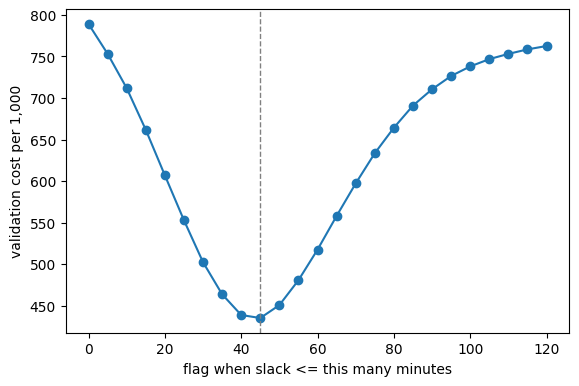

best cut-off: 45 min. Baseline TEST cost: 449.8


In [21]:
plt.plot(SLACK_CUTOFFS, valid_costs, "o-")
plt.axvline(best_cutoff, color="grey", ls="--", lw=1)
plt.xlabel("flag when slack <= this many minutes"); plt.ylabel("validation cost per 1,000")
plt.show()
base_cost = cost_per_1000(y_test, base_flag)
print(f"best cut-off: {best_cutoff} min. Baseline TEST cost: {base_cost:.1f}")

## 5. The readable model: a depth-3 decision tree
A flowchart of at most three questions that a non-expert can follow.

In [ ]:
# This is how I decided what THRESHOLDS to use for the decision tree by evaluationg the cost per 1,000 turnarounds on the validation set
# Training a depth 3 decsiosn tree on the 2023 dataset then try every threshold from 0.05 to 0.95 keeping only the lowest cost

THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.05), 2)

tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
tree.fit(train[FEATURES], train["y"])
tree_probabilities = tree.predict_proba(valid[FEATURES])[:, 1]
valid_costs_tree = []
for t in THRESHOLDS:
    flag = tree_probabilities >= t
    cost = cost_per_1000(y_valid, flag)
    valid_costs_tree.append(cost)

tree_t = THRESHOLDS[np.argmin(valid_costs_tree)]
test_probabilities = tree.predict_proba(test[FEATURES])[:, 1]
tree_flag = test_probabilities >= tree_t

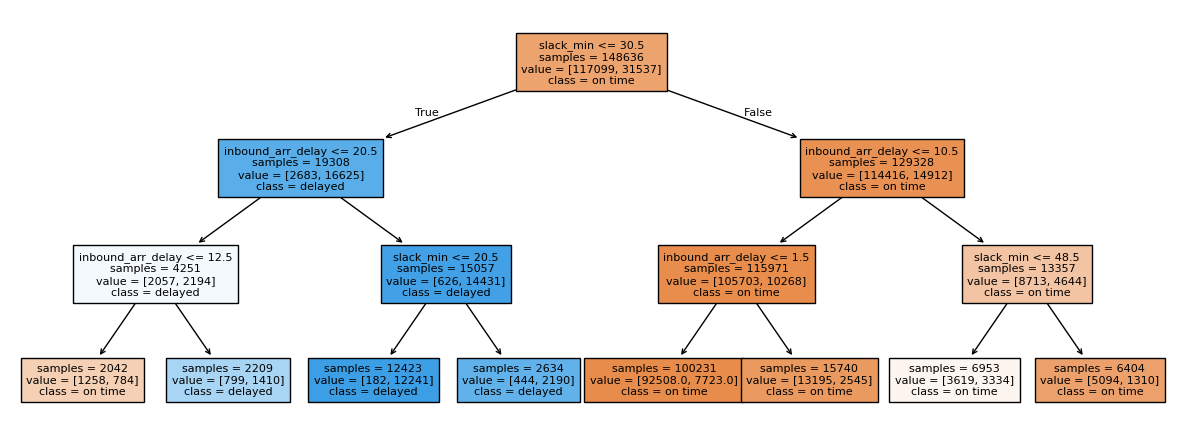

threshold 0.2. Tree TEST cost: 428.1   (baseline 449.8)


In [23]:
fig, ax = plt.subplots(figsize=(15, 5.5))
plot_tree(tree, feature_names=FEATURES, class_names=["on time", "delayed"],
          filled=True, impurity=False, fontsize=8, ax=ax)
plt.show()
tree_cost = cost_per_1000(y_test, tree_flag)
print(f"threshold {tree_t}. Tree TEST cost: {tree_cost:.1f}   (baseline {base_cost:.1f})")

We start at the root and check if the slack time is 30 minutes or less. Then the tree checks the inbound arrival delay. Unlike the baseline, this also uses how late the incoming flight arrives.

## 6. The flexible model: a random forest
I try a small grid of settings, pick the winner by **validation** cost, and then score it on the test set once.

In [ ]:
# Builds the random forest

GRID = [(depth, leaf) for depth in (8, 16, None) for leaf in (5, 50)] # How deep the trees will grow up to no litmit and the mind number of samples 

tuning = []      # (max_depth, min_samples_leaf, best threshold, validation cost)

for max_depth, min_samples_leaf in GRID: # Loops through the grid of max_depth and min_samples_leaf values to find the best combination based on validation cost
    forest = RandomForestClassifier(n_estimators=200, max_depth=max_depth, min_samples_leaf=min_samples_leaf,n_jobs=-1, random_state=SEED) # Creates a random forest classififer 
    forest.fit(train[FEATURES], train["y"]) # Fits the random forest classifier on the training data 
    valid_proba = forest.predict_proba(valid[FEATURES])[:, 1] # Get the predicted probabilities for the validation set
    valid_costs_forest = []
    for t in THRESHOLDS: # Loops through the thresholds to find the best threshold based on validation cost
        flag = valid_proba >= t #Use the threshold to create a flag for the validation set
        cost = cost_per_1000(y_valid, flag) # Calculate the cost per 1000 for the validation set using the current threshold
        valid_costs_forest.append(cost) 
    best_t = THRESHOLDS[np.argmin(valid_costs_forest)] #Gets the threshold that gives the minimum cost for the current max_depth and min_samples_leaf combination
    best_cost = min(valid_costs_forest)
    tuning.append((max_depth, min_samples_leaf, best_t, best_cost))

best_depth, best_leaf, forest_t, _ = min(tuning, key=lambda row: row[3]) # Find the combination of max_depth and min_samples_leaf that gives the minimum validation cost
forest = RandomForestClassifier(n_estimators=200, max_depth=best_depth, min_samples_leaf=best_leaf, n_jobs=-1, random_state=SEED) # Creates a random forest classififer with the best combination of max_depth and min_samples_leaf
forest.fit(train[FEATURES], train["y"]) # Fits the random forest classifier on the training data
forest_proba = forest.predict_proba(test[FEATURES])[:, 1] # Get the predicted probabilities for the test set
forest_flag = forest_proba >= forest_t # Flag turnarounds with predicted probabilities greater than or equal to the best threshold

In [46]:
print(pd.DataFrame(tuning, columns=["max_depth", "min_samples_leaf", "threshold", "valid cost"]).round(1))
forest_cost = cost_per_1000(y_test, forest_flag)
tn, fp, fn, tp = confusion_matrix(y_test, forest_flag).ravel()
print(f"\nForest TEST cost: {forest_cost:.1f}   (tree {tree_cost:.1f}, baseline {base_cost:.1f})")
print(f"recall {tp/(tp+fn):.1%}, precision {tp/(tp+fp):.1%}, flags {forest_flag.mean():.1%} of turnarounds")

   max_depth  min_samples_leaf  threshold  valid cost
0        8.0                 5        0.2       388.1
1        8.0                50        0.2       388.5
2       16.0                 5        0.2       386.9
3       16.0                50        0.2       386.2
4        NaN                 5        0.2       388.4
5        NaN                50        0.2       385.8

Forest TEST cost: 399.1   (tree 428.1, baseline 449.8)
recall 72.1%, precision 67.0%, flags 24.5% of turnarounds


The forest costs 399.1 per 1,000 turnarounds where the depth-3 tree costs 449.8 based on the slack baseline. This is about 7% better than the tree. At a threshold of 0.2 it catches about 72.1% of delays.

## 7. Bootstrap intervals
I resample the test rows with replacement 1,000 times, using the **same** resampled rows for every policy so the differences are paired.

In [ ]:
y = np.asarray(y_test) # numpy array for easier indexing
flags = [np.asarray(base_flag), np.asarray(tree_flag), np.asarray(forest_flag)] # Flags for the baseline, decision tree, and random forest models
boot = np.zeros((1000, 3)) #Bootstrap array to store the cost per 1000 for each model across 1000 iterations
for i in range(1000): # Preforming bootstrap resampling to estimate the variability of the cost per 1000 for each model
    idx = rng.integers(0, len(y_test), len(y_test))
    for j, flag in enumerate(flags):
        boot[i, j] = cost_per_1000(y[idx], flag[idx])

In [ ]:
for i, name in enumerate(["baseline", "tree", "forest"]): # Loop through the models and calculate the 95% confidence interval for the cost per 1000 using bootstrap resampling
    lo, hi = np.percentile(boot[:, i], [2.5, 97.5])
    print(f"{name:9s} 95% interval [{lo:.1f}, {hi:.1f}]")
lo, hi = np.percentile(boot[:, 2] - boot[:, 0], [2.5, 97.5])
print(f"forest minus baseline: [{lo:.1f}, {hi:.1f}]")
lo, hi = np.percentile(boot[:, 2] - boot[:, 1], [2.5, 97.5])
print(f"forest minus tree:     [{lo:.1f}, {hi:.1f}]")

baseline  95% interval [443.5, 455.8]
tree      95% interval [421.9, 434.6]
forest    95% interval [392.9, 405.3]
forest minus baseline: [-54.4, -47.0]
forest minus tree:     [-32.0, -26.0]


The forest and the tree both reliably beat the baseline. The forest is 47 to 54 per 1,000 cheaper than the baseline and 26 to 32 cheaper than the tree.

## 8. Does weather help?
My proposal asked whether weather improves the predictions. I refit the forest with the same settings and the weather columns removed.

In [ ]:
NO_WEATHER = [f for f in FEATURES if f not in
              ("wind_speed", "visibility", "precipitation", "weather_missing")] # remove weather features to see if the model can still perform well without them

forest_nowx = RandomForestClassifier(n_estimators=200, max_depth=best_depth, min_samples_leaf=best_leaf, n_jobs=-1, random_state=SEED) # Creates a random forest classifier without weather features
forest_nowx.fit(train[NO_WEATHER], train["y"])
nowx_valid_proba = forest_nowx.predict_proba(valid[NO_WEATHER])[:, 1] # Get the predicted probabilities for the validation set without weather features
nowx_costs = []
for t in THRESHOLDS: # Loops through the thresholds to find the best threshold based on validation cost for the model without weather features
    flag = nowx_valid_proba >= t
    nowx_costs.append(cost_per_1000(y_valid, flag))
nowx_t = THRESHOLDS[np.argmin(nowx_costs)]
nowx_flag = forest_nowx.predict_proba(test[NO_WEATHER])[:, 1] >= nowx_t

In [ ]:
nowx_cost = cost_per_1000(y_test, nowx_flag) # Calculate the cost per 1000 for the test set using the best threshold for the model without weather features
diffs = []
for _ in range(1000): # Preforming bootstrap resampling to estimate the variability of the difference in cost per 1000 between the model with weather features and the model without weather features
    idx = rng.integers(0, len(y_test), len(y_test))
    diffs.append(cost_per_1000(y_test[idx], forest_flag[idx]) - cost_per_1000(y_test[idx], nowx_flag[idx])) # calculate the difference in cost per 1000 between the model with weather features 
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"with weather {forest_cost:.1f}, without {nowx_cost:.1f}; difference 95% interval [{lo:.1f}, {hi:.1f}]")

with weather 399.1, without 399.2; difference 95% interval [-1.3, 1.0]


Weather did not help. This is probably because I think the inbound delay already included weather information.

## 9. Airport clusters: do the misses concentrate in one type of airport?
I cluster airports by how they operate (no labels used), then check whether the forest's **missed delays** pile up in one cluster.

In [ ]:
# K means clustering to group airports based on their characteristics and delay rates. This can help identify patterns and similarities among airports, which may inform strategies for managing delays.
profile = train.groupby("airport").agg(n=("y", "size"), median_sched_turn_min=("sched_turn_min", "median"), mean_distance=("next_distance", "mean"), mean_dep_hour=("next_dep_hour", "mean"))
profile = profile[profile["n"] >= 100]
profile["log_n"] = np.log10(profile["n"])  # Use log_n instead of n to reduce the influence of airports with very high counts on the clustering
profile = profile.drop(columns="n")  # Drop the original count column since we have log_n now
X = StandardScaler().fit_transform(profile) # Standardize the features to have mean 0 and variance 1, which is important for K-means clustering since it is sensitive to the scale of the data
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED) # Apply K-means clustering to group airports into 3 clusters based on their characteristics and delay rates
profile["cluster"] = kmeans.fit_predict(X)

In [38]:
print(profile.groupby("cluster").mean().round(2))
print(profile["cluster"].value_counts().sort_index())

         median_sched_turn_min  mean_distance  mean_dep_hour  log_n
cluster                                                            
0                        47.32         610.02          14.57   2.57
1                        61.25         960.45          14.52   3.34
2                        45.43         629.76          13.86   2.35
cluster
0    60
1    36
2    34
Name: count, dtype: int64


In [ ]:
# Here I evaluate the prefroamcne of the rand forest model on the test set by the cluster
t = test.copy()
t["cluster"] = t["airport"].map(profile["cluster"]).fillna(-1).astype(int)
t["flag"]=np.asarray(forest_flag)
rows = []
for cluster, group in t.groupby("cluster"): # Loop through each cluster and calculate the number of turnarounds, number of delays, miss rate, and 95% confidence interval for the miss rate using bootstrap resampling
    caught = group.loc[group["y"] == 1, "flag"].to_numpy()
    miss_rate = 1 - caught.mean()
    boot_miss = []
    for _ in range(500): # Preforming bootstrap resampling to estimate the variability of the miss rate for each cluster
        idx = rng.integers(0, len(caught), len(caught))
        boot_miss.append(1 - caught[idx].mean())
    lo, hi = np.percentile(boot_miss, [2.5, 97.5]) # Calculate the 95% confidence interval for the miss rate using bootstrap resampling
    rows.append((cluster, len(group), group["y"].sum(), miss_rate, lo, hi))
cluster_table = pd.DataFrame(rows, columns=["airport group", "test turnarounds", "delays", "miss rate", "low", "high"]) # Create a DataFrame to store the results for each cluster

cluster_table = pd.DataFrame(rows)

In [70]:
names = {-1: "Too small to cluster", 0: "Smaller airports", 1: "Hubs", 2: "Smallest airports"}
cluster_table = pd.DataFrame(rows, columns=["airport group", "test turnarounds", "delays", "miss rate", "low", "high"])
print(cluster_table.round(3).to_string())
overall_miss = 1 - forest_flag[y_test == 1].mean()
print(f"\noverall miss rate: {overall_miss:.3f}") # 

   airport group  test turnarounds  delays  miss rate    low   high
0             -1              7215    1619      0.214  0.196  0.233
1              0             30443    7339      0.216  0.208  0.225
2              1            101690   22902      0.311  0.305  0.317
3              2              9811    2109      0.203  0.186  0.219

overall miss rate: 0.279


The cluster of large airports has the highest miss rate, so the forest's misses concentrate at hubs. This changes how the operations team should use the model, because it suggests that more of their delays have causes other than late inbound traffic, which the features can't always see.

## 10. Failure analysis: where does the forest do worst?
I slice the **test** results by two variables chosen before looking: **carrier** and **time of day** of the next departure. Each slice shows its sample size and an interval.

In [ ]:
results = test.assign(
    flag=forest_flag, base_flag=base_flag,
    time_of_day=pd.cut(test["next_dep_hour"], [0, 10, 14, 18, 24], right=False,
                       labels=["before 10", "10-14", "14-18", "18 or later"])) # Categorize the time of day for each test instance

def slice_table(column):
    rows = []
    for value, group in results.groupby(column, observed=True): # Loop through each group based on the specified column and calculate the number of turnarounds, mean delay rate, cost per 1000 turnarounds, and 95% confidence interval for the cost per 1000 using bootstrap resampling
        y = group["y"].to_numpy()
        flag = group["flag"].to_numpy()
        base = group["base_flag"].to_numpy()

        boot_cost = []
        for _ in range(500): # Bootstrap resampling to estimate the variability of the cost per 1000 for each group
            idx = rng.integers(0, len(y), len(y))
            boot_cost.append(cost_per_1000(y[idx], flag[idx]))
        lo, hi = np.percentile(boot_cost, [2.5, 97.5]) # 95% confidence interval for the cost per 1000 using bootstrap resampling
        rows.append((value, len(group), group["y"].mean(), cost_per_1000(y, flag), lo, hi, cost_per_1000(y, base), (flag[y == 1]).mean())) # Append the results for the current group to the list of rows, including the group value, number of turnarounds, mean delay rate, cost per 1000 for the forest model, lower and upper bounds of the 95% confidence interval for the cost per 1000, cost per 1000 for the baseline model, and recall for the forest model
    return pd.DataFrame(rows, columns=[column, "n", "delay_rate", "forest_cost", "lo", "hi", "base_cost", "recall"]).sort_values("forest_cost", ascending=False)

In [60]:
print(slice_table("carrier").round(3).to_string(index=False))
print()
print(slice_table("time_of_day").round(3).to_string(index=False))

carrier     n  delay_rate  forest_cost      lo      hi  base_cost  recall
     B6  4036       0.281      519.326 475.799 562.686    573.588   0.680
     UA 15589       0.196      488.550 467.378 511.130    523.767   0.569
     AA 18451       0.249      436.941 419.892 455.668    463.931   0.707
     F9  4353       0.290      431.427 392.798 472.921    467.494   0.747
     AS  5225       0.235      405.550 371.574 439.809    439.426   0.733
     NK  4028       0.235      401.440 363.797 439.120    412.612   0.706
     WN 32528       0.279      396.950 385.218 410.974    431.567   0.779
     DL 21551       0.197      394.831 377.404 411.049    446.476   0.650
     OH  5591       0.251      378.644 350.027 410.575    466.822   0.784
     HA  1829       0.147      361.946 313.546 411.154    787.862   0.680
     YX  7506       0.191      351.985 325.580 375.769    411.804   0.731
     MQ  6556       0.189      337.706 315.196 362.801    451.647   0.785
     OO 18966       0.175      323.579

The worst slice is JetBlue at 519 per 1,000.

## 11. The decision
**Recommendation.** They should deploy the random forest, flagging a turnaround when the predicted turnaround time is .20 or higher. It beats the baseline by 47 to 54 and the tree by 26 to 32, catching 72% of delays.

**What would reverse it.** The cost ratio.

**Who bears each error.** A miss falls on the passengers and crew. If the flight leaves 15 minutes late with no warning, connections would be missed.

## AI use
I used Claude (Anthropic) to write `prepare_data.py`, set up this notebook's structure, review my code and help with the report figures. What it got wrong and how I caught it is in the AI appendix of the report.